In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset, Dataset
import pandas as pd
import numpy as np

import experiment
import clslib
import analysis

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
temp_train_df = dataset["train"].to_pandas()
temp_val_df = dataset["validation"].to_pandas()
dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

C:\Users\PCUser\AppData\Roaming\Python\Python310\site-packages\numpy\core\fromnumeric.py:59: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset, vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

bow_encoder = clslib.BagOfWords(bpe_tokenizer.get_vocab(), bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
# hidden_dim=128
# dropout=0.1
# batch_size=64
# learning_rate=1e-3
# weight_decay=1e-4
# num_epochs=10
# device='cpu'

# metrics_for_all, best_epoch, best_preds = smlp.train_neural_network_model(
#     my_cross_validation_sets[0][0]["training"],  # remember to index datasets by [run][fold]
#     my_cross_validation_sets[0][0]["validation"],  # remember to index datasets by [run][fold]
#     num_classes=1,
#     encoder=bow_encoder, 
#     save_to=f'{results_folder}/tmpmodel',
#     hidden_dim=hidden_dim, 
#     dropout=dropout, 
#     batch_size=batch_size, 
#     learning_rate=learning_rate,
#     weight_decay=weight_decay, 
#     num_epochs=num_epochs,
#     device='cpu'
# )

In [6]:
hidden_dim=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['singleMLP_bow-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/singleMLP_bow-enc/seed-{seed}"
    my_classifiers['singleMLP_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': hidden_dim, 
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.856 seconds
Dataloader done! Time taken: 0.056 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\smlp.py:68: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.6958 | train acc: 0.5566 | val loss: 0.6774 | val acc: 0.5671
Epoch 02 | train loss: 0.6786 | train acc: 0.5743 | val loss: 0.6853 | val acc: 0.5650
Epoch 03 | train loss: 0.6730 | train acc: 0.5785 | val loss: 0.6686 | val acc: 0.5892
Epoch 04 | train loss: 0.6701 | train acc: 0.5827 | val loss: 0.6669 | val acc: 0.5918
Epoch 05 | train loss: 0.6685 | train acc: 0.5862 | val loss: 0.6668 | val acc: 0.5929
Epoch 06 | train loss: 0.6671 | train acc: 0.5897 | val loss: 0.6658 | val acc: 0.5933
Epoch 07 | train loss: 0.6652 | train acc: 0.5929 | val loss: 0.6673 | val acc: 0.5857
Epoch 08 | train loss: 0.6644 | train acc: 0.5916 | val loss: 0.6631 | val acc: 0.5965
Epoch 09 | train loss: 0.6623 | train acc: 0.5967 | val loss: 0.6641 | val acc: 0.5922
Epoch 10 | train loss: 0.6619 | train acc: 0.5970 | val loss: 0.6625 | val acc: 0.5932
Training done! Time taken: 75.956 seconds
Transforming documents...
Document transformation done! Time taken: 2.764 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7052 | train acc: 0.5491 | val loss: 0.6756 | val acc: 0.5822
Epoch 02 | train loss: 0.6796 | train acc: 0.5719 | val loss: 0.6737 | val acc: 0.5806
Epoch 03 | train loss: 0.6746 | train acc: 0.5776 | val loss: 0.6706 | val acc: 0.5896
Epoch 04 | train loss: 0.6721 | train acc: 0.5822 | val loss: 0.6703 | val acc: 0.5809
Epoch 05 | train loss: 0.6698 | train acc: 0.5849 | val loss: 0.6683 | val acc: 0.5936
Epoch 06 | train loss: 0.6686 | train acc: 0.5871 | val loss: 0.6667 | val acc: 0.5914
Epoch 07 | train loss: 0.6675 | train acc: 0.5885 | val loss: 0.6649 | val acc: 0.5941
Epoch 08 | train loss: 0.6653 | train acc: 0.5966 | val loss: 0.6630 | val acc: 0.5931
Epoch 09 | train loss: 0.6641 | train acc: 0.5950 | val loss: 0.6629 | val acc: 0.5930
Epoch 10 | train loss: 0.6639 | train acc: 0.5927 | val loss: 0.6627 | val acc: 0.5988
Training done! Time taken: 71.079 seconds
Transforming documents...
Document transformation done! Time taken: 2.839 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6972 | train acc: 0.5574 | val loss: 0.6806 | val acc: 0.5667
Epoch 02 | train loss: 0.6784 | train acc: 0.5750 | val loss: 0.6749 | val acc: 0.5752
Epoch 03 | train loss: 0.6735 | train acc: 0.5815 | val loss: 0.6735 | val acc: 0.5737
Epoch 04 | train loss: 0.6704 | train acc: 0.5852 | val loss: 0.6713 | val acc: 0.5804
Epoch 05 | train loss: 0.6681 | train acc: 0.5906 | val loss: 0.6697 | val acc: 0.5845
Epoch 06 | train loss: 0.6661 | train acc: 0.5907 | val loss: 0.6702 | val acc: 0.5846
Epoch 07 | train loss: 0.6649 | train acc: 0.5913 | val loss: 0.6693 | val acc: 0.5810
Epoch 08 | train loss: 0.6637 | train acc: 0.5958 | val loss: 0.6682 | val acc: 0.5888
Epoch 09 | train loss: 0.6625 | train acc: 0.5949 | val loss: 0.6678 | val acc: 0.5842
Epoch 10 | train loss: 0.6613 | train acc: 0.5978 | val loss: 0.6679 | val acc: 0.5852
Training done! Time taken: 69.378 seconds


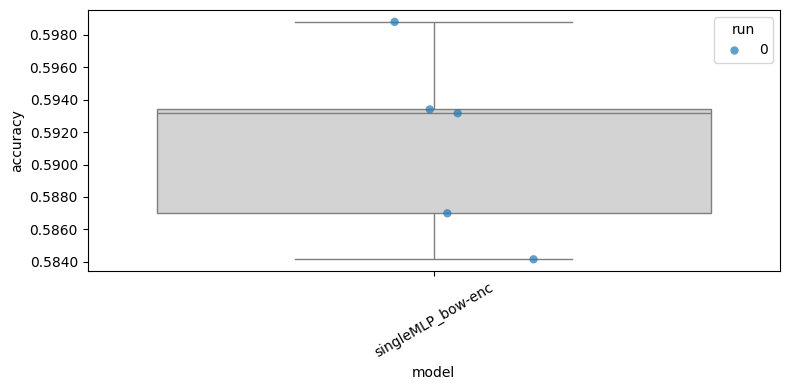

In [7]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))